<h1>Тут видимо будут эксперименты со стэкингом</h1>

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='darkgrid')

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, auc, average_precision_score, roc_curve, precision_recall_curve, f1_score

In [15]:
X_train = pd.read_csv('../data/train_X.csv').fillna(0) #[['agg_spark_extended_report__g_contractor__CreditLimitSum__last__ALL_TIME','contract_init_sum', 'contract_current_sum', 'contract_id']]
final_test = pd.read_csv('../data/test1_X.csv').fillna(0)
y_train = pd.read_csv('../data/train_y.csv')['default6']

In [16]:
X_train = X_train.drop(['report_date', 'contract_date'], axis=1)

In [8]:
unique_contract_ids = X_train['contract_id'].unique()
train_meta_ids, test_ids = train_test_split(unique_contract_ids, test_size=0.2, random_state=42)

train_meta_mask = X_train['contract_id'].isin(train_meta_ids)
test_mask = X_train['contract_id'].isin(test_ids)

X_train_meta = X_train[train_meta_mask] 
y_train_meta = y_train[train_meta_mask]

X_test = X_train[test_mask].drop(columns=['contract_id'])
y_test = y_train[test_mask]

train_meta_unique_ids = X_train_meta['contract_id'].unique()


train_base_ids, meta_ids = train_test_split(train_meta_unique_ids, test_size=0.25, random_state=42)

train_base_mask = X_train_meta['contract_id'].isin(train_base_ids)
meta_mask = X_train_meta['contract_id'].isin(meta_ids)

X_train_base = X_train_meta[train_base_mask].drop(columns=['contract_id'])
y_train_base = y_train_meta[train_base_mask]

X_meta = X_train_meta[meta_mask].drop(columns=['contract_id'])
y_meta = y_train_meta[meta_mask]
X_train_meta = X_train_meta.drop(columns=['contract_id'])

In [9]:
print(f"X_train_meta shape: {X_train_meta.shape}, y_train_meta shape: {y_train_meta.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

X_train_meta shape: (23192, 167), y_train_meta shape: (23192,)
X_test shape: (5639, 167), y_test shape: (5639,)


In [10]:
print(f"X_train_base shape: {X_train_base.shape}, y_train_base shape: {y_train_base.shape}")
print(f"X_meta shape: {X_meta.shape}, y_meta shape: {y_meta.shape}")
print(f"X test (all rows) shape: {X_test.shape}")

X_train_base shape: (17410, 167), y_train_base shape: (17410,)
X_meta shape: (5782, 167), y_meta shape: (5782,)
X test (all rows) shape: (5639, 167)


In [11]:
base_models = [
    ('catboost', CatBoostClassifier(iterations=1000, learning_rate=0.1, depth=5, early_stopping_rounds=50, random_seed=42, verbose=0)),
    ('xgboost', XGBClassifier(n_estimators=1000, learning_rate=0.1, max_depth=5, early_stopping_rounds=50, eval_metric='auc', random_state=42, use_label_encoder=False, verbosity=0)),
    ('lightgbm', lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.1, max_depth=5, early_stopping_rounds=50, random_state=42, verbosity=0)),
    ('randomforest', RandomForestClassifier(n_estimators=500, max_depth=10, random_state=42))
]
meta_features = [] # мета фичи (вероятности от base моделек)
for name, model in base_models:
    if name in ['catboost', 'xgboost', 'lightgbm']: # случайный лес скипаем короч
        model.fit(X_train_base, y_train_base, eval_set=[(X_meta, y_meta)])
    else:
        model.fit(X_train_base, y_train_base)
    
    meta_pred = model.predict_proba(X_meta)[:, 1]
    meta_features.append(meta_pred)
    
    auc = roc_auc_score(y_meta, meta_pred)
    gini = 2 * auc - 1
    print(f'Base model {name} Gini Score on base data: {gini}')

meta_features = np.column_stack(meta_features)

meta_model = LogisticRegression()
meta_model.fit(meta_features, y_meta)

test_meta_features = []
for name, model in base_models:
    test_pred = model.predict_proba(X_test)[:, 1]
    test_meta_features.append(test_pred)

test_meta_features = np.column_stack(test_meta_features)
y_pred_proba = meta_model.predict_proba(test_meta_features)[:, 1]

final_auc = roc_auc_score(y_test, y_pred_proba)
final_gini = 2 * final_auc - 1
print(f'Final Stacking Model Gini Score (No threshold): {final_gini}')
# тут я трешхолды считал, можете раскомментить если че
# final_auc_thresh = roc_auc_score(y_test, (y_pred_proba >= 0.5).astype(int))
# final_gini_thresh = 2 * final_auc_thresh - 1
# print(f'Final Stacking Model Gini Score (Threshold: 0.5): {final_gini_thresh}')
# thresholds = np.linspace(0, 1, 101)
# auc_score_thresholds = []
# for i in range(len(thresholds)):
#     outputs = (y_pred_proba >= thresholds[i]).astype(int)
#     auc_score_thresholds.append(roc_auc_score(y_test, outputs))
# auc_score_thresholds = np.array(auc_score_thresholds)
# print(f'Final Stacking Model Gini Score (Best Threshold: {thresholds[np.argmax(auc_score_thresholds)]}): {2*auc_score_thresholds.max()-1}')


Base model catboost Gini Score on base data: 0.5643276650897775
[0]	validation_0-auc:0.61161
[1]	validation_0-auc:0.67701
[2]	validation_0-auc:0.67215
[3]	validation_0-auc:0.68267
[4]	validation_0-auc:0.69481
[5]	validation_0-auc:0.70204
[6]	validation_0-auc:0.70198
[7]	validation_0-auc:0.68919
[8]	validation_0-auc:0.68615
[9]	validation_0-auc:0.69986
[10]	validation_0-auc:0.70584
[11]	validation_0-auc:0.70710
[12]	validation_0-auc:0.71090
[13]	validation_0-auc:0.71578
[14]	validation_0-auc:0.71924
[15]	validation_0-auc:0.71905
[16]	validation_0-auc:0.72556
[17]	validation_0-auc:0.72342
[18]	validation_0-auc:0.72227
[19]	validation_0-auc:0.72205
[20]	validation_0-auc:0.71889
[21]	validation_0-auc:0.72266
[22]	validation_0-auc:0.72524
[23]	validation_0-auc:0.72511
[24]	validation_0-auc:0.72741
[25]	validation_0-auc:0.72741
[26]	validation_0-auc:0.72855
[27]	validation_0-auc:0.72961
[28]	validation_0-auc:0.73206
[29]	validation_0-auc:0.73350
[30]	validation_0-auc:0.73195
[31]	validation_

Best Threshold: 0.12
AUC Score: 0.8010
Precision: 0.3477
Recall: 0.7480
Матрица ошибок:
[[3483 1259]
 [ 226  671]]


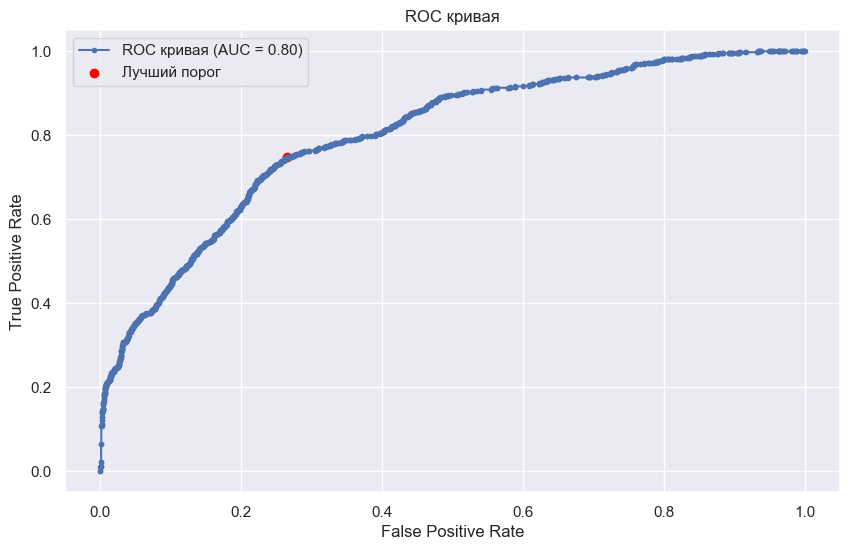

In [9]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

auc_score = roc_auc_score(y_test, y_pred_proba)

distances = np.sqrt((fpr - 0)**2 + (tpr - 1)**2)
best_idx = np.argmin(distances)
best_threshold = thresholds[best_idx]

y_pred_best = (y_pred_proba >= best_threshold).astype(int)

print(f'Best Threshold: {best_threshold:.2f}')
print(f'AUC Score: {auc_score:.4f}')

from sklearn.metrics import precision_score, recall_score, confusion_matrix
precision = precision_score(y_test, y_pred_best)
recall = recall_score(y_test, y_pred_best)
conf_matrix = confusion_matrix(y_test, y_pred_best)

print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'Матрица ошибок:\n{conf_matrix}')

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, marker='.', label=f'ROC кривая (AUC = {auc_score:.2f})')
plt.scatter(fpr[best_idx], tpr[best_idx], color='red', marker='o', label='Лучший порог')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC кривая')
plt.legend()
plt.grid(True)
plt.show()


In [10]:
f1_score(y_test, y_pred_best)

0.47470817120622566

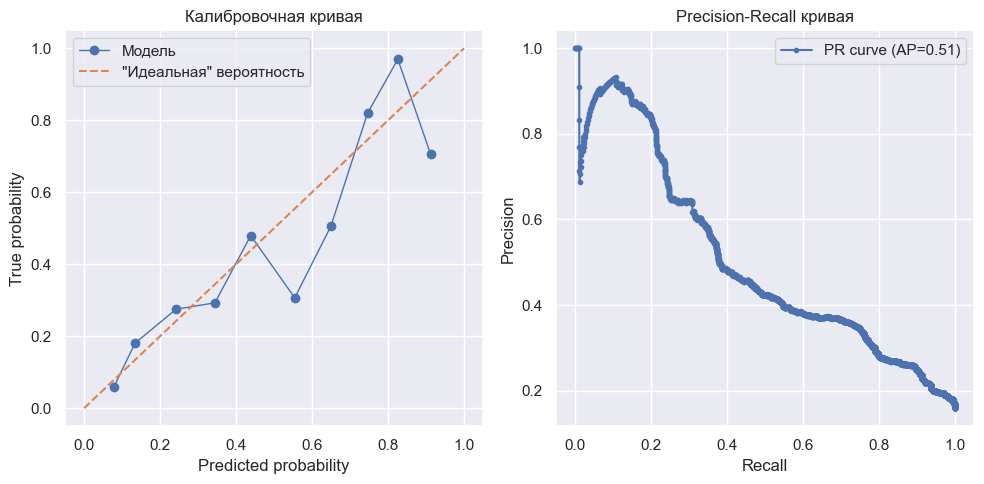

Calibration metrics:
Predicted probabilities: [0.07801634 0.13394211 0.24173703 0.34438801 0.43860442 0.55441238
 0.64955675 0.74616393 0.82575586 0.91196953]
True probabilities: [0.05819936 0.18038409 0.27488152 0.29281768 0.4796748  0.30666667
 0.50574713 0.82       0.96969697 0.70588235]
Average Precision Score: 0.51


In [11]:
prob_true, prob_pred = calibration_curve(y_test, y_pred_proba, n_bins=10)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(prob_pred, prob_true, marker='o', linewidth=1, label='Модель')
plt.plot([0, 1], [0, 1], linestyle='--', label='"Идеальная" вероятность')
plt.xlabel('Predicted probability')
plt.ylabel('True probability')
plt.title('Калибровочная кривая')
plt.legend()

precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
average_precision = average_precision_score(y_test, y_pred_proba)
plt.subplot(1, 2, 2)
plt.plot(recall, precision, marker='.', label=f'PR curve (AP={average_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall кривая')
plt.legend()

plt.tight_layout()
plt.show()

# Print metrics
print(f'Calibration metrics:\nPredicted probabilities: {prob_pred}\nTrue probabilities: {prob_true}')
print(f'Average Precision Score: {average_precision:.2f}')


Calibrated Meta Model for Stackin Gini Score (No threshold): 0.6017429107851422


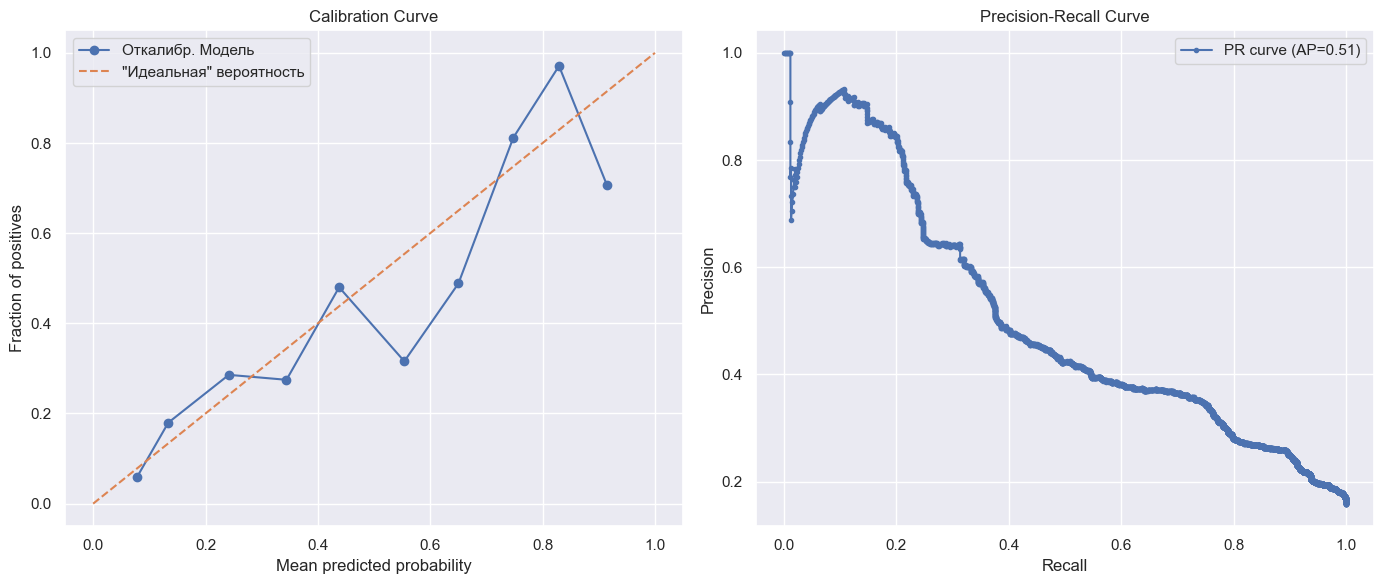

AUC Score: 0.8009
Average Precision Score: 0.5058


In [12]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import roc_auc_score, brier_score_loss, auc

calibrated_meta_model = CalibratedClassifierCV(estimator=meta_model, method='sigmoid')
calibrated_meta_model.fit(meta_features, y_meta)

y_pred_proba_calibrated = calibrated_meta_model.predict_proba(test_meta_features)[:, 1]

auc_score = roc_auc_score(y_test, y_pred_proba_calibrated)
print(f'Calibrated Meta Model for Stackin Gini Score (No threshold): {2*auc_score-1}')

precision, recall, _ = precision_recall_curve(y_test, y_pred_proba_calibrated)
average_precision = auc(recall, precision)

prob_true, prob_pred = calibration_curve(y_test, y_pred_proba_calibrated, n_bins=10)

plt.figure(figsize=(14, 6))


plt.subplot(1, 2, 1)
plt.plot(prob_pred, prob_true, marker='o', label='Откалибр. Модель')
plt.plot([0, 1], [0, 1], linestyle='--', label='"Идеальная" вероятность')
plt.xlabel('Mean predicted probability')
plt.ylabel('Fraction of positives')
plt.title('Calibration Curve')
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(recall, precision, marker='.', label=f'PR curve (AP={average_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()

plt.tight_layout()
plt.show()

print(f'AUC Score: {auc_score:.4f}')
print(f'Average Precision Score: {average_precision:.4f}')

<h2>Как видим, нихрена особо не поменялось</h2>

In [13]:
from sklearn.base import BaseEstimator
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier
import numpy as np

class StackingModel(BaseEstimator):
    def __init__(self):
        # Инициализируем модели
        self.base_models = [
            ('catboost', CatBoostClassifier(iterations=1000, learning_rate=0.1, depth=5,
                                            early_stopping_rounds=50, random_seed=42, verbose=0)),
            ('xgboost', XGBClassifier(n_estimators=1000, learning_rate=0.1, max_depth=5,
                                      early_stopping_rounds=50, eval_metric='auc', random_state=42,
                                      use_label_encoder=False, verbosity=0)),
            ('lightgbm', lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.1, max_depth=5,
                                            early_stopping_rounds=50, random_state=42, verbosity=0)),
            ('randomforest', RandomForestClassifier(n_estimators=500, max_depth=10, random_state=42))
        ]
        self.meta_model = LogisticRegression()

    def fit(self, X_train_base, y_train_base, X_meta, y_meta):
        meta_features = []  # Сохраняем мета-фичи 

        # Train each base model
        for name, model in self.base_models:
            if name in ['catboost', 'xgboost', 'lightgbm']:
                model.fit(X_train_base, y_train_base, eval_set=[(X_meta, y_meta)])
            else:
                model.fit(X_train_base, y_train_base)

            # Предсказываем мета-фичи
            meta_pred = model.predict_proba(X_meta)[:, 1]
            meta_features.append(meta_pred)

            # Считаем и выводим Gini score
            auc = roc_auc_score(y_meta, meta_pred)
            gini = 2 * auc - 1
            print(f'Base model {name} Gini Score on meta data: {gini:.4f}')

        # стакаем мета фичи и обучаем логрег
        self.meta_features_ = np.column_stack(meta_features)
        self.meta_model.fit(self.meta_features_, y_meta)

    def predict_proba(self, X_test):
        test_meta_features = []

        # Предсказываем вероятности с помощью base моделей
        for name, model in self.base_models:
            test_pred = model.predict_proba(X_test)[:, 1]
            test_meta_features.append(test_pred)

        test_meta_features = np.column_stack(test_meta_features)
        return self.meta_model.predict_proba(test_meta_features)[:, 1]

    def evaluate(self, X_test, y_test):
        # Считаем вероятности и метрику
        y_pred_proba = self.predict_proba(X_test)
        auc = roc_auc_score(y_test, y_pred_proba)
        gini = 2 * auc - 1
        print(f'Final Stacking Model Gini Score (No threshold): {gini:.4f}')
        return gini

# Использование
# Инициализируем модель
stacking_model = StackingModel()

# Обучаем ее
stacking_model.fit(X_train_base, y_train_base, X_meta, y_meta)

# Считаем метрику и фиксируем прибыль
stacking_model.evaluate(X_test, y_test)


Base model catboost Gini Score on meta data: 0.5261
[0]	validation_0-auc:0.61161
[1]	validation_0-auc:0.67864
[2]	validation_0-auc:0.67248
[3]	validation_0-auc:0.68489
[4]	validation_0-auc:0.69519
[5]	validation_0-auc:0.70160
[6]	validation_0-auc:0.70494
[7]	validation_0-auc:0.69275
[8]	validation_0-auc:0.68066
[9]	validation_0-auc:0.69871
[10]	validation_0-auc:0.70570
[11]	validation_0-auc:0.70925
[12]	validation_0-auc:0.71226
[13]	validation_0-auc:0.71292
[14]	validation_0-auc:0.71603
[15]	validation_0-auc:0.71649
[16]	validation_0-auc:0.72196
[17]	validation_0-auc:0.72065
[18]	validation_0-auc:0.72414
[19]	validation_0-auc:0.72066
[20]	validation_0-auc:0.72064
[21]	validation_0-auc:0.72439
[22]	validation_0-auc:0.72641
[23]	validation_0-auc:0.72850
[24]	validation_0-auc:0.73220
[25]	validation_0-auc:0.73194
[26]	validation_0-auc:0.73307
[27]	validation_0-auc:0.73272
[28]	validation_0-auc:0.73441
[29]	validation_0-auc:0.73462
[30]	validation_0-auc:0.73432
[31]	validation_0-auc:0.7379

0.6019375706170857

In [16]:
from sklearn.cluster import Birch

birch = Birch()
cluster_labels = birch.fit_predict(X_train.drop('contract_id', axis=1))

X_train_with_clusters = X_train.copy()
X_train_with_clusters = X_train_with_clusters.drop('contract_id', axis=1)
X_train_with_clusters['cluster'] = cluster_labels

clustered_data = {label: X_train_with_clusters[X_train_with_clusters['cluster'] == label] 
                  for label in np.unique(cluster_labels)}

for cluster_label, data in clustered_data.items():
    print(f"Cluster {cluster_label}: {data.shape[0]} samples")

# Example usage: Accessing data for a specific cluster
# cluster_0_data = clustered_data[0]


Cluster 0: 7620 samples
Cluster 1: 12077 samples
Cluster 2: 9134 samples


In [17]:
def get_cluster_models(X_data, y_data, Clustering, Model):
    X_train = X_data.copy()
    cluster_labels = Clustering.predict(X_train.drop('contract_id', axis=1))
    X_train['cluster'] = cluster_labels
    X_train['target'] = y_data
    clustered_data = {label: X_train[X_train['cluster'] == label] 
                  for label in np.unique(cluster_labels)}
    for cluster_id, data in clustered_data.items():
        print(f'Processing and fitting model on the cluster №{cluster_id} ...')
        X = data.drop('target')
        y = data['target']
        unique_contract_ids = X['contract_id'].unique()
        train_meta_ids, test_ids = train_test_split(unique_contract_ids, test_size=0.2, random_state=42)

        train_meta_mask = X['contract_id'].isin(train_meta_ids)
        test_mask = X['contract_id'].isin(test_ids)

        X_train_meta = X[train_meta_mask] 
        y_train_meta = y[train_meta_mask]

        X_test = X[test_mask].drop(columns=['contract_id'])
        y_test = y[test_mask]

        train_meta_unique_ids = X_train_meta['contract_id'].unique()


        train_base_ids, meta_ids = train_test_split(train_meta_unique_ids, test_size=0.25, random_state=42)

        train_base_mask = X_train_meta['contract_id'].isin(train_base_ids)
        meta_mask = X_train_meta['contract_id'].isin(meta_ids)

        X_train_base = X_train_meta[train_base_mask].drop(columns=['contract_id'])
        y_train_base = y_train_meta[train_base_mask]

        X_meta = X_train_meta[meta_mask].drop(columns=['contract_id'])
        y_meta = y_train_meta[meta_mask]
        X_train_meta = X_train_meta.drop(columns=['contract_id'])

In [18]:
get_cluster_models(X_train, y_train, birch, StackingModel)

Processing and fitting model on the cluster №0
Processing and fitting model on the cluster №1
Processing and fitting model on the cluster №2


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

class SimpleMLP(nn.Module):
    def __init__(self, input_size):
        super(SimpleMLP, self).__init__()
        self.fc1 = nn.Linear(input_size, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.sigmoid = nn.Sigmoid()
    
    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return self.sigmoid(x)

class PyTorchMLP(BaseEstimator):
    def __init__(self, input_size, learning_rate=0.001, epochs=100, batch_size=32, early_stopping_rounds=10):
        self.model = SimpleMLP(input_size)
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.early_stopping_rounds = early_stopping_rounds
        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.criterion = nn.BCELoss()
    
    def fit(self, X, y, X_val, y_val):
        self.model.train()
        X_tensor = torch.tensor(X, dtype=torch.float32)
        y_tensor = torch.tensor(y.values, dtype=torch.float32).view(-1, 1)
        X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
        y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1)
        
        best_val_loss = np.inf
        patience = 0
        
        for epoch in range(self.epochs):
            permutation = torch.randperm(X_tensor.size()[0])
            for i in range(0, X_tensor.size()[0], self.batch_size):
                indices = permutation[i:i+self.batch_size]
                batch_x, batch_y = X_tensor[indices], y_tensor[indices]
                
                self.optimizer.zero_grad()
                outputs = self.model(batch_x)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
            
            # Early stopping
            with torch.no_grad():
                self.model.eval()
                val_outputs = self.model(X_val_tensor)
                val_loss = self.criterion(val_outputs, y_val_tensor)
                self.model.train()
                
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                patience = 0
            else:
                patience += 1
                if patience >= self.early_stopping_rounds:
                    break
    
    def predict_proba(self, X):
        self.model.eval()
        X_tensor = torch.tensor(X, dtype=torch.float32)
        with torch.no_grad():
            outputs = self.model(X_tensor)
        return outputs.numpy()

class StackingModel(BaseEstimator):
    def __init__(self, input_size):
        # Initialize base models
        self.base_models = [
            ('catboost', CatBoostClassifier(iterations=1000, learning_rate=0.1, depth=5,
                                            early_stopping_rounds=50, random_seed=42, verbose=0)),
            ('xgboost', XGBClassifier(n_estimators=1000, learning_rate=0.1, max_depth=5,
                                      early_stopping_rounds=50, eval_metric='auc', random_state=42,
                                      use_label_encoder=False, verbosity=0)),
            ('lightgbm', lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.1, max_depth=5,
                                            early_stopping_rounds=50, random_state=42, verbosity=0)),
            ('randomforest', RandomForestClassifier(n_estimators=500, max_depth=10, random_state=42)),
            ('mlp', PyTorchMLP(input_size=input_size, epochs=100, early_stopping_rounds=10))
        ]
        self.meta_model = LogisticRegression()

    def fit(self, X_train_base, y_train_base, X_meta, y_meta):
        meta_features = []  # Meta features to train the meta-model
        
        # Train each base model
        for name, model in self.base_models:
            if name in ['catboost', 'xgboost', 'lightgbm']:
                model.fit(X_train_base, y_train_base, eval_set=[(X_meta, y_meta)], verbose=0)
            elif name == 'mlp':
                X_train_base_np = X_train_base.to_numpy()
                X_meta_np = X_meta.to_numpy()
                model.fit(X_train_base_np, y_train_base, X_meta_np, y_meta)
            else:
                model.fit(X_train_base, y_train_base)

            # Predict meta features
            if name == 'mlp':
                meta_pred = model.predict_proba(X_meta.to_numpy())
            else:
                meta_pred = model.predict_proba(X_meta)[:, 1]
            meta_features.append(meta_pred)

            # Calculate and print Gini score
            auc = roc_auc_score(y_meta, meta_pred)
            gini = 2 * auc - 1
            print(f'Base model {name} Gini Score on meta data: {gini:.4f}')

        # Stack meta features and train the meta-model
        self.meta_features_ = np.column_stack(meta_features)
        self.meta_model.fit(self.meta_features_, y_meta)

    def predict_proba(self, X_test):
        test_meta_features = []

        # Predict probabilities using base models
        for name, model in self.base_models:
            if name == 'mlp':
                test_pred = model.predict_proba(X_test.to_numpy())
            else:
                test_pred = model.predict_proba(X_test)[:, 1]
            test_meta_features.append(test_pred)

        test_meta_features = np.column_stack(test_meta_features)
        return self.meta_model.predict_proba(test_meta_features)[:, 1]

    def evaluate(self, X_test, y_test):
        # Calculate probabilities and metrics
        y_pred_proba = self.predict_proba(X_test)
        auc = roc_auc_score(y_test, y_pred_proba)
        gini = 2 * auc - 1
        print(f'Final Stacking Model Gini Score (No threshold): {gini:.4f}')
        return gini


# stacking_model = StackingModel(input_size=X_train_base.shape[1])
# stacking_model.fit(X_train_base, y_train_base, X_meta, y_meta)
# stacking_model.evaluate(X_test, y_test)
